# TWPA gain and system noise vs frequency

1. **Gain** from the TWPA VNA gain run (`VNA_RUN`): S21 with the pump off and on, $G_\mathrm{TWPA} = |S_{21,\mathrm{on}}/S_{21,\mathrm{off}}|^2$.
2. **System noise** from the TWPA noise spectrum run (`RUN`): SA spectra, hot wire 0 V / on × pump off / on.

Both over 5.5–6.5 GHz at the same 401 frequencies, flux bias 0 V.

**Pump off.** At each frequency $P = a_\mathrm{off}\,[T_N^\mathrm{HE} + T_\mathrm{add,off}]$. $a_\mathrm{off}$ (W/K) turns a noise
temperature at the qubit plane into the power the SA reads with the pump off, $a_\mathrm{off} = k_B\,B_\mathrm{ENBW}\,G_\mathrm{chain,off}$:
everything from the qubit plane to the SA (the unpumped TWPA, HEMT, warm amplifiers, cables, ENBW, SA response), one
number per frequency, measured here, so neither $G_\mathrm{chain,off}$ nor the ENBW is needed. The hot-wire noise at the
qubit plane comes from the wire calibration (`../2_wire_calibration`):

- hot wire 0 V: $T_N^\mathrm{HE} = hf/2k_B$
- hot wire on: $T_N^\mathrm{HE} = \eta\,\frac{hf}{2k_B}\coth\frac{hf}{2k_BT^\mathrm{eff}} + (1 - \eta)\,\frac{hf}{2k_B}$, with
  $\eta$, $k_V$ and $V_0$ (for $T^\mathrm{eff}$ at this run's bias) loaded from the earlier hot-wire calibration fit
  (`WIRE_FIT_CSV`, zero-span Y factor at 5.576 GHz) and evaluated at every $f$ here

The hot wire's step gives the chain and the system noise:

$$a_\mathrm{off} = \frac{P_\mathrm{off}(\mathrm{on}) - P_\mathrm{off}(0\,\mathrm{V})}{T_{N,\mathrm{on}}^\mathrm{HE} - T_{N,\mathrm{0\,V}}^\mathrm{HE}}, \qquad
T_\mathrm{sys,off} = \frac{P_\mathrm{off}(0\,\mathrm{V})}{a_\mathrm{off}}$$

**Pump on.** The pump changes only the TWPA, by the VNA gain: $G_\mathrm{chain,on} = G_\mathrm{chain,off}\,G_\mathrm{TWPA}$, so
$a_\mathrm{on} = a_\mathrm{off}\,G_\mathrm{TWPA}$ and

$$T_\mathrm{sys,on} = \frac{P_\mathrm{on}(0\,\mathrm{V})}{a_\mathrm{off}\,G_\mathrm{TWPA}}$$

Noise the TWPA brings to $f$ from other bands (idler, sidebands, harmonics) is all in $T_\mathrm{sys,on}$. Taking out
the input's half photon and the chain after the TWPA ($T_\mathrm{add,off}/G_\mathrm{TWPA}$) leaves the noise the TWPA adds, referred to
its input:

$$T_\mathrm{add}^\mathrm{TWPA} = T_\mathrm{sys,on} - \frac{hf}{2k_B} - \frac{T_\mathrm{sys,off} - hf/2k_B}{G_\mathrm{TWPA}}$$

against $\frac{hf}{2k_B}\big(1 - \frac{1}{G_\mathrm{TWPA}}\big)$ for an ideal two-mode amplifier. $\eta$ comes from 5.576 GHz and is taken
as the same over the span.

In [25]:
import json
import numpy as np
import matplotlib.pyplot as plt

kB = 1.380649e-23
h = 6.62607015e-34
e = 1.602176634e-19

## Parameters

In [42]:
VNA_RUN = "8_52ghz_6dbm_vna.json"                       # TWPA VNA gain
RUN = "8_52ghz_6dbm_sa.json"                 # TWPA noise spectrum
WIRE_FIT_CSV = "../2_wire_calibration/hotwire-qubit-plane-fit.csv"   # k_V, V0, eta, T_add in its first line
SMOOTH = 1                                # running mean for the plots (21 x 2.5 MHz = 52.5 MHz)
BANDS_HZ = 100e6                           # band width in the table

## Gain (VNA)

pump 8.52 GHz 6 dBm; 2 rounds x 10 traces per state, VNA -25 dBm, attenuator 25 dB, flux 0 V
gain 13.12 dB mean, 8.46..25.31 dB


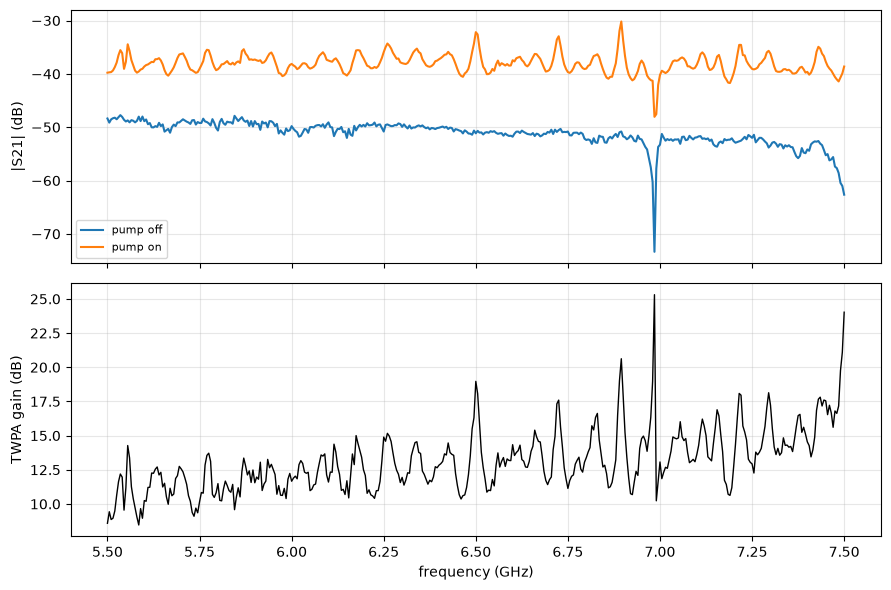

In [43]:
with open(VNA_RUN) as fh:
    v = json.load(fh)
f = np.array(v["frequency_hz"])
s_off = np.array(v["s21_off_real"]) + 1j * np.array(v["s21_off_imag"])    # each averaged over the rounds
s_on = np.array(v["s21_on_real"]) + 1j * np.array(v["s21_on_imag"])
gain_db = 20 * np.log10(np.abs(s_on / s_off))
G_twpa = 10 ** (gain_db / 10)
print(f"pump {v['pump_frequency_hz'] / 1e9:g} GHz {v['pump_power_dbm']:g} dBm; {v['params']['rounds']} rounds x "
      f"{v['params']['averages']} traces per state, VNA {v['vna_power_dbm']:g} dBm, attenuator "
      f"{v['attenuator_state']['attenuation_db']:g} dB, flux {v['flux_bias_state']['level']:g} V")
print(f"gain {gain_db.mean():.2f} dB mean, {gain_db.min():.2f}..{gain_db.max():.2f} dB")

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(f / 1e9, 20 * np.log10(np.abs(s_off)), label="pump off")
ax[0].plot(f / 1e9, 20 * np.log10(np.abs(s_on)), label="pump on")
ax[0].set(ylabel="|S21| (dB)")
ax[0].legend(fontsize=8)
ax[1].plot(f / 1e9, gain_db, "k", lw=1)
ax[1].set(ylabel="TWPA gain (dB)", xlabel="frequency (GHz)")
for a_ in ax:
    a_.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## System noise (SA spectra)

In [44]:
with open(RUN) as fh:
    d = json.load(fh)
assert np.allclose(d["frequency_hz"], f)
assert np.isclose(d["pump_frequency_hz"], v["pump_frequency_hz"]) and d["pump_power_dbm"] == v["pump_power_dbm"]
P = {(pump, wire): np.array(d["power_w"][f"pump_{pump}_wire_{wire}"]) for pump in ("off", "on") for wire in ("0", "on")}
V_on, T0 = d["hot_wire_on_v"], d["fridge_temperature_k"]

head = open(WIRE_FIT_CSV).readline()
fit = dict(kV=float(head.split("k_V ")[1].split()[0]), V0=float(head.split("V0 ")[1].split()[0]),
           eta=float(head.split("eta ")[1].split(",")[0]), T_add=float(head.split("T_add ")[1].split()[0]))

def T_eff(Vw):
    # hot-wire electron temperature at the wire voltage Vw
    nu = max(np.sqrt(3) / (2 * np.pi) * e * abs(Vw) / (kB * T0), 1e-9)
    return T0 / 2 * (1 + (nu + 1 / nu) * np.arctan(nu))

Te = T_eff(fit["kV"] * 1e-3 * (V_on - fit["V0"] * 1e-3))
T_half = h * f / (2 * kB)
dTN = fit["eta"] * (T_half / np.tanh(T_half / Te) - T_half)     # T_N^HE(on) - T_N^HE(0 V)
print(f"{d['params']['rounds']} rounds x {d['params']['traces']} x {d['sweep_time_s']:g} s per state; hot wire "
      f"{V_on:g} V: T_eff = {Te:.3f} K, T_N^HE on = {(T_half + dTN).mean():.3f} K")

a_off = (P["off", "on"] - P["off", "0"]) / dTN
T_sys = {"off": P["off", "0"] / a_off, "on": P["on", "0"] / (a_off * G_twpa)}
T_twpa = T_sys["on"] - T_half - (T_sys["off"] - T_half) / G_twpa
n = 2 * T_half                          # k_B T / hf = T / n photons
QL = 0.5 * (1 - 1 / G_twpa)                 # TWPA added noise of an ideal two-mode amplifier, photons

def smooth(x):                          # running mean over SMOOTH points, fewer at the ends
    k = np.ones(SMOOTH)
    return np.convolve(x, k, mode="same") / np.convolve(np.ones_like(x), k, mode="same")

edges = np.arange(f[0], f[-1] + 1, BANDS_HZ)
print(f"\n{'':12} {'':>9} {'T_sys (K)':^17} {'photons':^27}")
print(f"{'band (GHz)':>12} {'gain (dB)':>9} {'off':>8} {'on':>8} {'T_sys on':>9} {'TWPA add':>9} {'QL add':>7}")
rows = [(f"{lo/1e9:5.1f}-{hi/1e9:3.1f}  ", (f >= lo) & (f < hi)) for lo, hi in zip(edges[:-1], edges[1:])]
for name, m in rows + [("  whole span", np.ones_like(f, dtype=bool))]:
    print(f"{name:>12} {gain_db[m].mean():9.2f} {T_sys['off'][m].mean():8.2f} {T_sys['on'][m].mean():8.2f} "
          f"{(T_sys['on'] / n)[m].mean():9.2f} {(T_twpa / n)[m].mean():9.2f} {QL[m].mean():7.2f}")

T_cal = fit["T_add"] + h * 5.576e9 / (2 * kB)
print(f"\npump-off T_sys at 5.576 GHz: {smooth(T_sys['off'])[np.argmin(np.abs(f - 5.576e9))]:.2f} K "
      f"(zero-span calibration {T_cal:.2f} K)")

2 rounds x 2 x 10 s per state; hot wire 0.1 V: T_eff = 1.911 K, T_N^HE on = 1.623 K

                           T_sys (K)               photons          
  band (GHz) gain (dB)      off       on  T_sys on  TWPA add  QL add
   5.5-5.6       10.38     7.53     1.26      4.75      1.59    0.45
   5.6-5.7       11.48     8.47     1.24      4.56      1.79    0.46
   5.7-5.8       11.18     7.20     1.16      4.20      1.67    0.46
   5.8-5.9       11.41     7.85     1.22      4.34      1.79    0.46
   5.9-6.0       11.74     8.14     1.17      4.08      1.67    0.47
   6.0-6.1       12.32     8.45     1.16      4.00      1.78    0.47
   6.1-6.2       12.61     8.89     1.17      3.96      1.74    0.47
   6.2-6.3       12.47     7.67     1.13      3.76      1.75    0.47
   6.3-6.4       12.61     7.82     1.10      3.60      1.68    0.47
   6.4-6.5       12.81     8.22     1.16      3.76      1.76    0.47
   6.5-6.6       13.27     8.75     1.18      3.76      1.84    0.47
   6.6-6.7       1

Spectra; $T_\mathrm{sys}$ with the pump off and on, and the TWPA added noise in photons (points: every
frequency, lines: running mean; red: the ideal two-mode amplifier).

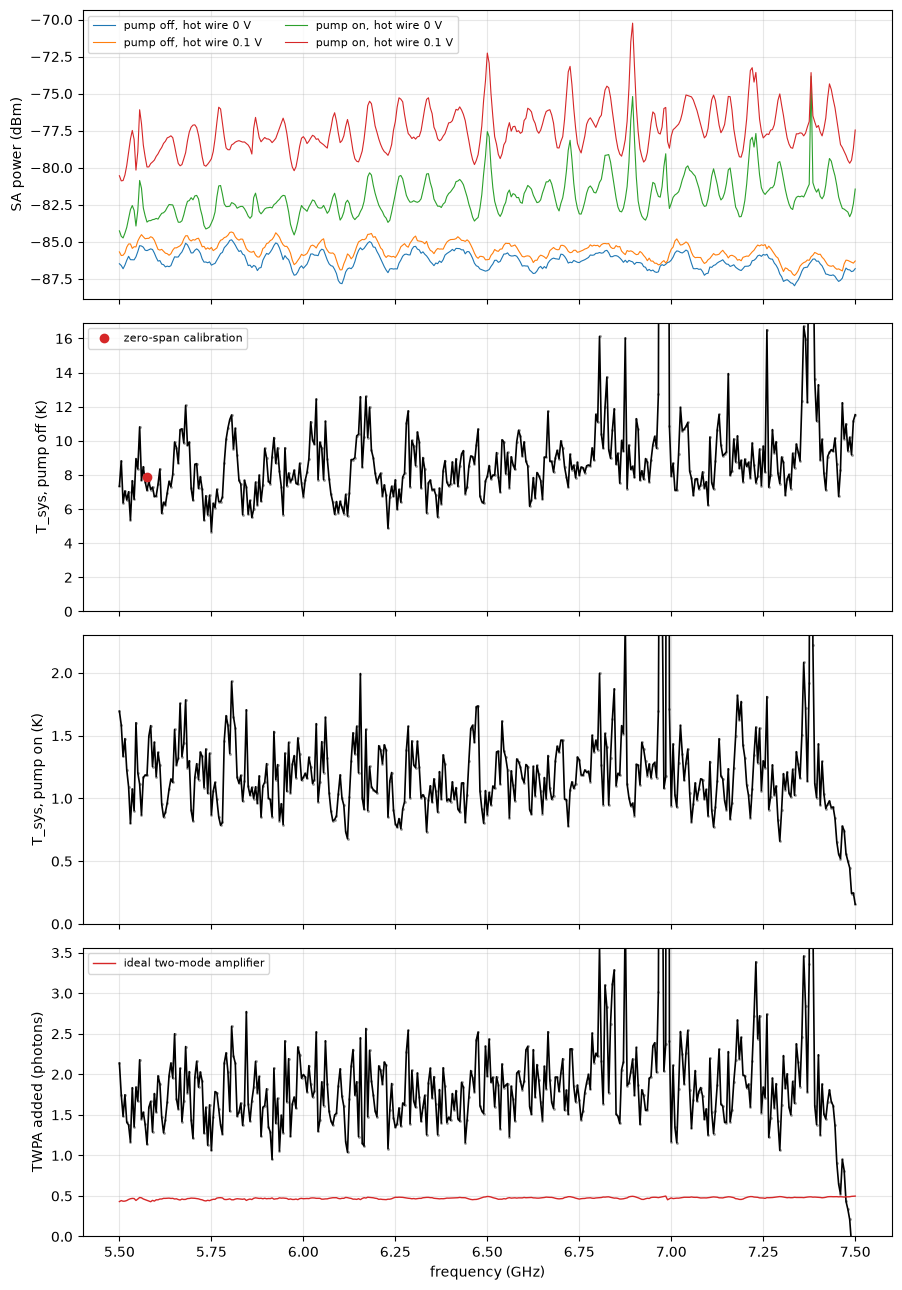

In [45]:
fx = f / 1e9
fig, ax = plt.subplots(4, 1, figsize=(9, 13), sharex=True)
for (pump, wire), c in zip(P, ("C0", "C1", "C2", "C3")):
    ax[0].plot(fx, 10 * np.log10(P[pump, wire] / 1e-3), c, lw=0.8,
               label=f"pump {pump}, hot wire {wire if wire == '0' else format(V_on, 'g')} V")
ax[0].set(ylabel="SA power (dBm)")
ax[0].legend(fontsize=8, ncol=2)
for i, (y, label) in enumerate(((T_sys["off"], "T_sys, pump off (K)"), (T_sys["on"], "T_sys, pump on (K)"),
                                (T_twpa / n, "TWPA added (photons)"))):
    ax[1 + i].plot(fx, y, ".", color="0.6", ms=2)
    ax[1 + i].plot(fx, smooth(y), "k", lw=1.2)
    ax[1 + i].set(ylabel=label, ylim=(0, 2 * np.median(y)))
ax[1].plot(5.576, T_cal, "o", color="C3", label="zero-span calibration")
ax[1].legend(fontsize=8)
ax[3].plot(fx, QL, "C3", lw=1, label="ideal two-mode amplifier")
ax[3].legend(fontsize=8)
ax[3].set(xlabel="frequency (GHz)")
for a_ in ax:
    a_.grid(alpha=0.3)
fig.tight_layout()
plt.show()